In [1]:
from collections import Counter
import heapq
import math
import numpy as np
from scipy.fft import dct, idct
import matplotlib.pyplot as plt
from struct import unpack, pack

In [2]:
def nuB(x: int):
    lims = np.arange(3)
    lims = 2**lims
    lims *= 8
    lims = 2**lims
    for nB, lim in enumerate(lims.tolist()):
        if x < lim:
            return 2**nB
    return 2**3


nuB(1e9)

4

In [ ]:
f = open("Wildlife.wmv", "rb")
lenchunk = 0x100  ##########
chunk = f.read(lenchunk)
if len(chunk) < lenchunk:
    chunk += b"\x00" * (lenchunk - len(chunk))
x = unpack("<" + "b" * lenchunk, chunk)
x = np.array(x)
x

array([  48,   38,  -78,  117, -114,  102,  -49,   17,  -90,  -39,    0,
        -86,    0,   98,  -50,  108,   48,   22,    0,    0,    0,    0,
          0,    0,    8,    0,    0,    0,    1,    2,   64,  -92,  -48,
        -46,    7,  -29,  -46,   17, -105,  -16,    0,  -96,  -55,   94,
        -88,   80,  -52,    0,    0,    0,    0,    0,    0,    0,    4,
          0,   28,    0,   83,    0,  102,    0,   79,    0,  114,    0,
        105,    0,  103,    0,  105,    0,  110,    0,   97,    0,  108,
          0,   70,    0,   80,    0,   83,    0,    0,    0,    3,    0,
          4,    0,  -76, -110,    4,    0,   28,    0,   87,    0,   77,
          0,   70,    0,   83,    0,   68,    0,   75,    0,   86,    0,
        101,    0,  114,    0,  115,    0,  105,    0,  111,    0,  110,
          0,    0,    0,    0,    0,   30,    0,   49,    0,   49,    0,
         46,    0,   48,    0,   46,    0,   54,    0,   48,    0,   48,
          0,   49,    0,   46,    0,   55,    0,   

In [ ]:
coef = dct(x, n=lenchunk)
abscoef = np.abs(coef)
scoef = np.sort(abscoef)
n_eliminated = lenchunk * 1 // 2  ##########
absthreshold = scoef[n_eliminated]
fcoef = np.where(np.abs(coef) < absthreshold, 0, coef)
kcoef = min(0x7FFF / fcoef.max(), -0x8000 / fcoef.min())  ##########
ncoef = np.rint(fcoef * kcoef).astype(int)
lenchunk - n_eliminated, kcoef, unpack("d", pack("d", kcoef)), ncoef.max(), ncoef.min()

(128,
 np.float64(3.382923807557299),
 (3.382923807557299,),
 np.int64(32767),
 np.int64(-13626))

In [5]:
reconstructed = idct(ncoef / kcoef, n=lenchunk)
reconstructed = np.rint(reconstructed).astype(np.int64)
reconstructed

array([  46,   46,  -74,  109, -121,   89,  -58,   24,  -81,  -33,    8,
        -73,   10,  101,  -40,  112,   32,   37,   17,   -9,   -1,   -8,
        -10,   -3,   11,   -5,   -7,   10,   12,    0,   63,  -80,  -37,
        -41,  -20,  -44,  -42,   22,  -86,  -20,    4,  -89,  -64,   87,
        -97,   73,  -42,    5,   -8,    4,   -1,  -15,    1,   17,   11,
          5,   20,   -1,   98,    5,  102,   -8,   73,  -12,  113,   -4,
         97,   -4,   96,    1,  101,    4,  105,   -1,   99,    7,  105,
        -14,   79,    0,   87,   -4,   80,    7,   -9,    0,   -1,   -5,
        -11,   -3,  -67, -104,    4,   -7,   36,   -9,   89,    3,   70,
         16,   58,  -13,   85,    4,   59,  -19,   81,    6,   80,   -5,
        106,   -9,  117,    0,  100,    2,  114,   14,  109,    9,  109,
        -15,    9,    2,   -3,    0,   26,    6,   66,   -7,   43,   -4,
         40,   10,   39,    4,   47,  -23,   57,   18,   47,   -3,   47,
        -15,   50,    0,   47,   19,   57,    8,   

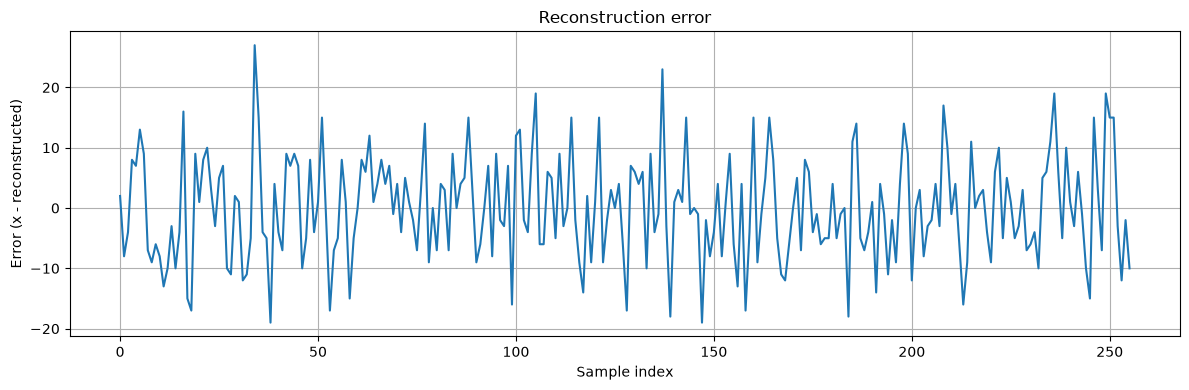

In [6]:
dxr = x - reconstructed
plt.figure(figsize=(12, 4))
plt.plot(dxr)
plt.xlabel("Sample index")
plt.ylabel("Error (x - reconstructed)")
plt.title("Reconstruction error")
plt.grid(True)
plt.tight_layout()
plt.show()

Symbols: 40
Encoded payload: 1,283 bits = 161 bytes


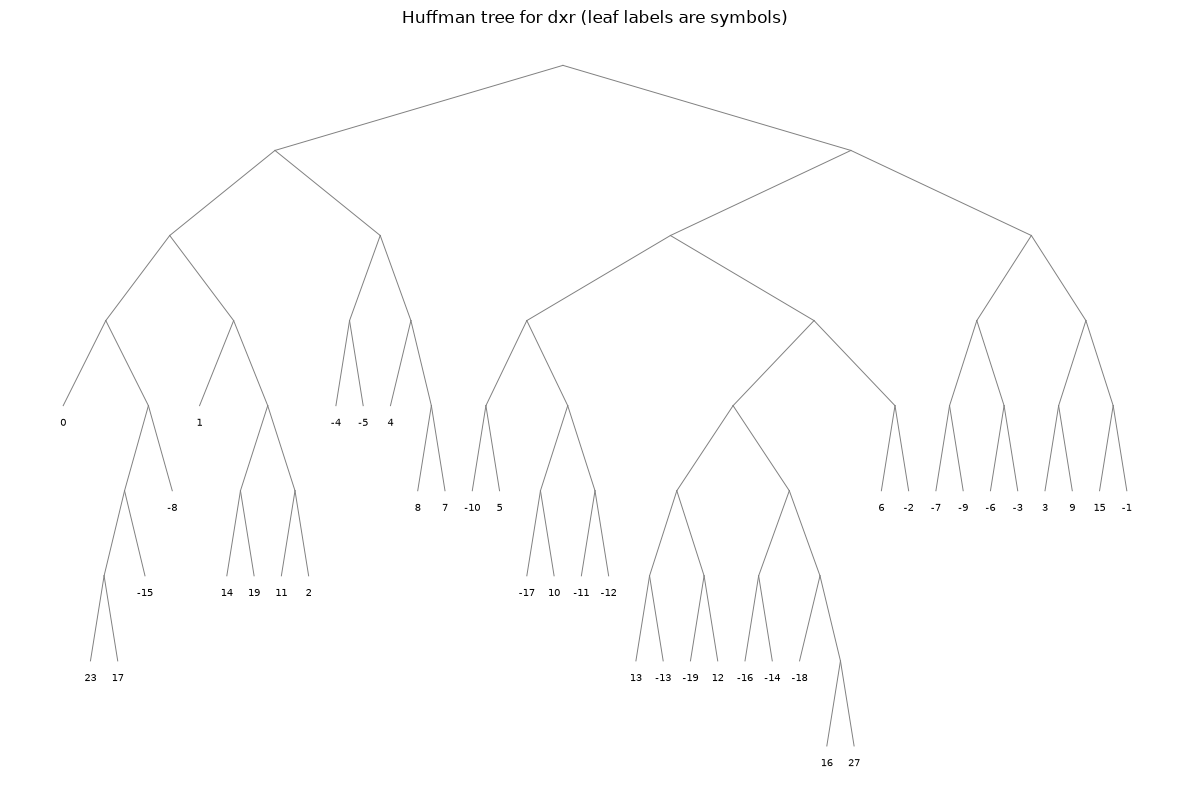

In [7]:
dxr_freq = Counter(int(v) for v in dxr)
if not dxr_freq:
    raise ValueError("dxr is empty")

huff_heap = []
huff_serial = 0

for symbol, frequency in dxr_freq.items():
    heapq.heappush(
        huff_heap,
        (frequency, huff_serial, {"symbol": symbol, "left": None, "right": None}),
    )
    huff_serial += 1

while len(huff_heap) > 1:
    freq_a, _, node_a = heapq.heappop(huff_heap)
    freq_b, _, node_b = heapq.heappop(huff_heap)
    parent = {"symbol": None, "left": node_a, "right": node_b}
    heapq.heappush(huff_heap, (freq_a + freq_b, huff_serial, parent))
    huff_serial += 1

huff_root = huff_heap[0][2]
huff_lengths = {}
huff_leaf_positions = []
huff_edges = []
huff_next_x = 0


def layout_huffman(node, depth=0):
    global huff_next_x

    if node["symbol"] is not None:
        x_pos = huff_next_x
        huff_next_x += 1
        huff_lengths[node["symbol"]] = max(1, depth)
        huff_leaf_positions.append((x_pos, -depth, node["symbol"]))
        return x_pos

    left_x = layout_huffman(node["left"], depth + 1)
    right_x = layout_huffman(node["right"], depth + 1)
    parent_x = (left_x + right_x) / 2
    huff_edges.extend(
        [
            ((parent_x, -depth), (left_x, -(depth + 1))),
            ((parent_x, -depth), (right_x, -(depth + 1))),
        ]
    )
    return parent_x


layout_huffman(huff_root)

huff_bits = sum(
    frequency * huff_lengths[symbol] for symbol, frequency in dxr_freq.items()
)
huff_bytes = (huff_bits + 7) // 8
print(f"Symbols: {len(dxr_freq)}")
print(f"Encoded payload: {huff_bits:,} bits = {huff_bytes:,} bytes")

fig, ax = plt.subplots(figsize=(max(12, len(dxr_freq) * 0.18), 8))
for (x1, y1), (x2, y2) in huff_edges:
    ax.plot([x1, x2], [y1, y2], color="gray", linewidth=0.7)

for x_pos, y_pos, symbol in huff_leaf_positions:
    ax.text(x_pos, y_pos - 0.15, str(symbol), ha="center", va="top", fontsize=7)

ax.set_title("Huffman tree for dxr (leaf labels are symbols)")
ax.axis("off")
plt.tight_layout()
plt.show()

Symbols: 22
Huffman payload: 1,053 bits = 132 bytes
Base storage: 32 bytes
Total: 164 bytes (excluding Huffman-tree metadata)


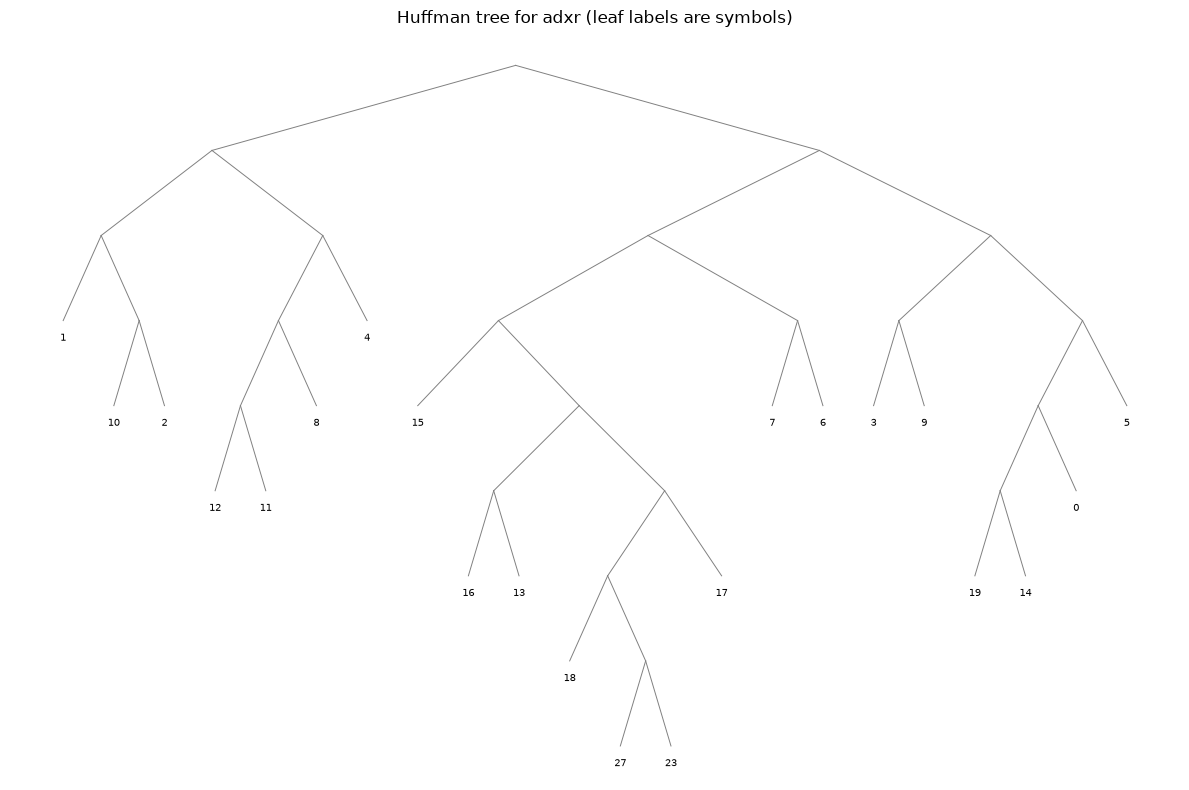

In [8]:
adxr = np.abs(dxr)
adxr_freq = Counter(int(v) for v in adxr)

adxr_heap = []
adxr_serial = 0
for symbol, frequency in adxr_freq.items():
    heapq.heappush(
        adxr_heap,
        (frequency, adxr_serial, {"symbol": symbol, "left": None, "right": None}),
    )
    adxr_serial += 1

while len(adxr_heap) > 1:
    freq_a, _, node_a = heapq.heappop(adxr_heap)
    freq_b, _, node_b = heapq.heappop(adxr_heap)
    parent = {"symbol": None, "left": node_a, "right": node_b}
    heapq.heappush(adxr_heap, (freq_a + freq_b, adxr_serial, parent))
    adxr_serial += 1

adxr_root = adxr_heap[0][2]
adxr_lengths = {}
adxr_edges = []
adxr_leaves = []
adxr_next_x = 0


def layout_adxr(node, depth=0):
    global adxr_next_x

    if node["symbol"] is not None:
        x_pos = adxr_next_x
        adxr_next_x += 1
        adxr_lengths[node["symbol"]] = max(1, depth)
        adxr_leaves.append((x_pos, -depth, node["symbol"]))
        return x_pos

    left_x = layout_adxr(node["left"], depth + 1)
    right_x = layout_adxr(node["right"], depth + 1)
    parent_x = (left_x + right_x) / 2
    adxr_edges.extend(
        [
            ((parent_x, -depth), (left_x, -(depth + 1))),
            ((parent_x, -depth), (right_x, -(depth + 1))),
        ]
    )
    return parent_x


layout_adxr(adxr_root)

adxr_bits = sum(
    frequency * adxr_lengths[symbol] for symbol, frequency in adxr_freq.items()
)
adxr_payload_bytes = (adxr_bits + 7) // 8
adxr_base_bytes = lenchunk // 8
adxr_total_bytes = adxr_base_bytes + adxr_payload_bytes

print(f"Symbols: {len(adxr_freq)}")
print(f"Huffman payload: {adxr_bits:,} bits = {adxr_payload_bytes:,} bytes")
print(f"Base storage: {adxr_base_bytes:,} bytes")
print(f"Total: {adxr_total_bytes:,} bytes (excluding Huffman-tree metadata)")

fig, ax = plt.subplots(figsize=(max(12, len(adxr_freq) * 0.18), 8))
for (x1, y1), (x2, y2) in adxr_edges:
    ax.plot([x1, x2], [y1, y2], color="gray", linewidth=0.7)

for x_pos, y_pos, symbol in adxr_leaves:
    ax.text(x_pos, y_pos - 0.15, str(symbol), ha="center", va="top", fontsize=7)

ax.set_title("Huffman tree for adxr (leaf labels are symbols)")
ax.axis("off")
plt.tight_layout()
plt.show()